In [1]:
import pandas as pd
import matplotlib.pyplot as plt

### Exploring and Cleaning

In [2]:
pizza_df = pd.read_csv("pizza_sales.csv")
pizza_df.head(2)

,pizza_id,order_id,pizza_name_id,quantity,order_date,order_time,unit_price,total_price,pizza_size,pizza_category,pizza_ingredients,pizza_name
0,1,1,hawaiian_m,1,01-01-2015,11:38:36,13.25,13.25,M,Classic,"Sliced Ham, Pineapple, Mozzarella Cheese",The Hawaiian Pizza
1,2,2,classic_dlx_m,1,01-01-2015,11:57:40,16.00,16.00,M,Classic,"Pepperoni, Mushrooms, Red Onions, Red Peppers,...",The Classic Deluxe Pizza


In [3]:
# dataSet shape
print("DataSet shape", pizza_df.shape)
# dataSet Info
print("DataSet info", pizza_df.info())

DataSet shape (48620, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48620 entries, 0 to 48619
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pizza_id           48620 non-null  int64  
 1   order_id           48620 non-null  int64  
 2   pizza_name_id      48620 non-null  object 
 3   quantity           48620 non-null  int64  
 4   order_date         48620 non-null  object 
 5   order_time         48620 non-null  object 
 6   unit_price         48620 non-null  float64
 7   total_price        48620 non-null  float64
 8   pizza_size         48620 non-null  object 
 9   pizza_category     48620 non-null  object 
 10  pizza_ingredients  48620 non-null  object 
 11  pizza_name         48620 non-null  object 
dtypes: float64(2), int64(3), object(7)
memory usage: 4.5+ MB
DataSet info None


In [4]:
# columns type
print("data sets dtypes", pizza_df.dtypes)

data sets dtypes pizza_id               int64
order_id               int64
pizza_name_id         object
quantity               int64
order_date            object
order_time            object
unit_price           float64
total_price          float64
pizza_size            object
pizza_category        object
pizza_ingredients     object
pizza_name            object
dtype: object


In [5]:
# change from object to datetime
pizza_df['order_date'] = pd.to_datetime(pizza_df["order_date"], dayfirst=True)
pizza_df["order_hour"] = pd.to_datetime(pizza_df["order_time"], format='%H:%M:%S').dt.hour
pizza_df["order_day"] = pizza_df['order_date'].dt.day_name()
pizza_df["order_month"] = pizza_df['order_date'].dt.month_name()
pizza_df[["order_date", "order_hour", "order_day", "order_month"]].dtypes

order_date     datetime64[ns]
order_hour              int32
order_day              object
order_month            object
dtype: object

In [6]:
# null checkment
if pizza_df.isnull().values.any():
    print('data set has null values')
    print(pizza_df.isnull.sum()[pizza_df.isnull().sum() > 0])
else:
    print('no null values')

no null values


In [7]:
# string Checkment
for col in ['pizza_size', 'pizza_category', 'pizza_name']:
    pizza_df[col] = pizza_df[col].astype(str).str.strip()

print('pizza sizes', pizza_df['pizza_size'].unique())
print('pizza Categories', pizza_df['pizza_category'].unique())
print('pizza names', pizza_df['pizza_name'].unique())

pizza sizes ['M' 'L' 'S' 'XL' 'XXL']
pizza Categories ['Classic' 'Veggie' 'Supreme' 'Chicken']
pizza names ['The Hawaiian Pizza' 'The Classic Deluxe Pizza' 'The Five Cheese Pizza'
 'The Italian Supreme Pizza' 'The Mexicana Pizza' 'The Thai Chicken Pizza'
 'The Prosciutto and Arugula Pizza' 'The Barbecue Chicken Pizza'
 'The Greek Pizza' 'The Spinach Supreme Pizza' 'The Green Garden Pizza'
 'The Italian Capocollo Pizza' 'The Spicy Italian Pizza'
 'The Spinach Pesto Pizza' 'The Vegetables + Vegetables Pizza'
 'The Southwest Chicken Pizza' 'The California Chicken Pizza'
 'The Pepperoni Pizza' 'The Chicken Pesto Pizza' 'The Big Meat Pizza'
 'The Soppressata Pizza' 'The Four Cheese Pizza' 'The Napolitana Pizza'
 'The Calabrese Pizza' 'The Italian Vegetables Pizza'
 'The Mediterranean Pizza' 'The Pepper Salami Pizza'
 'The Spinach and Feta Pizza' 'The Sicilian Pizza'
 'The Chicken Alfredo Pizza' 'The Pepperoni, Mushroom, and Peppers Pizza'
 'The Brie Carre Pizza']


In [8]:
# check duplicates
pizza_df.duplicated().sum()

np.int64(0)

### KPIs

In [9]:
total_revenue = pizza_df['total_price'].sum()
total_pizza = pizza_df["quantity"].sum()
total_orders = pizza_df['order_id'].nunique()
AOV = total_revenue / total_orders
APO = total_pizza / total_orders

print(f'total revenue : {total_revenue: ,.2f} ')
print(f'total pizaa sold : {total_pizza: ,}')
print(f'total orders : {total_orders: ,}')
print(f'Average Orders Value (AOV): {AOV: ,.2f}')
print(f'Average pizza per orders (APO): {APO: ,.2f}')

total revenue :  817,860.05 
total pizaa sold :  49,574
total orders :  21,350
Average Orders Value (AOV):  38.31
Average pizza per orders (APO):  2.32


## analytics and visualization

In [10]:
# ingrediants analysing
ingredients =(
    pizza_df['pizza_ingredients']
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
    .reset_index()
    .rename(columns={'index': 'counts', "pizza_ingredients": "ingrediants"})
)
print(ingredients.head(5))

         ingrediants  count
0             Garlic  27422
1           Tomatoes  26601
2         Red Onions  19547
3        Red Peppers  16284
4  Mozzarella Cheese  10333


#### sales per day

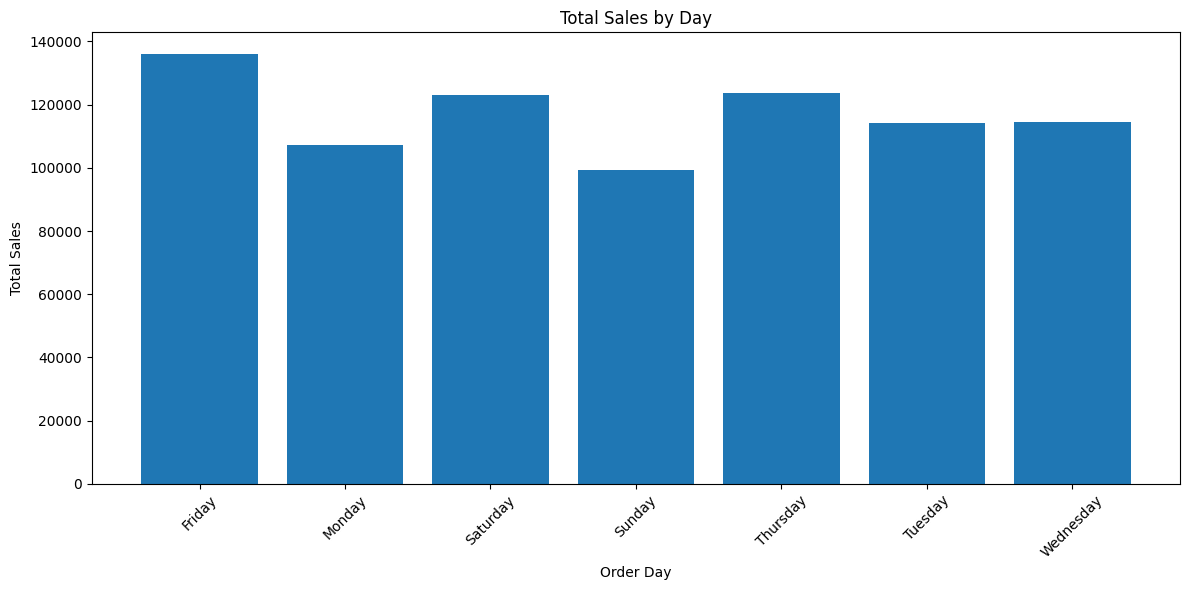

In [11]:
sales_by_day = pizza_df.groupby('order_day')['total_price'].sum()

plt.figure(figsize=(12, 6))
plt.bar(sales_by_day.index, sales_by_day.values)
plt.title('Total Sales by Day')
plt.xlabel('Order Day')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### sales per hour

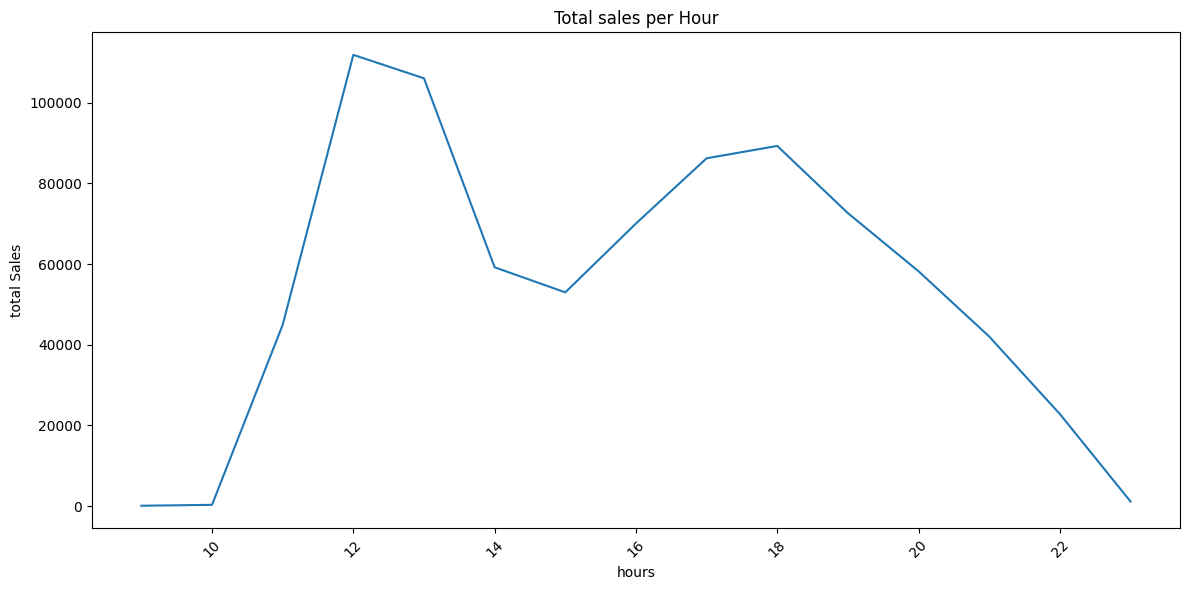

In [12]:
sales_by_hour = pizza_df.groupby('order_hour')['total_price'].sum()
plt.figure(figsize=(12, 6))
plt.plot(sales_by_hour.index, sales_by_hour.values)
plt.title('Total sales per Hour')
plt.xlabel('hours')
plt.ylabel('total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### sales per month

array([<Axes: title={'center': 'Orders by Month'}, xlabel='order_month'>,
       <Axes: title={'center': 'Total Revenue by Month'}, xlabel='order_month'>],
      dtype=object)

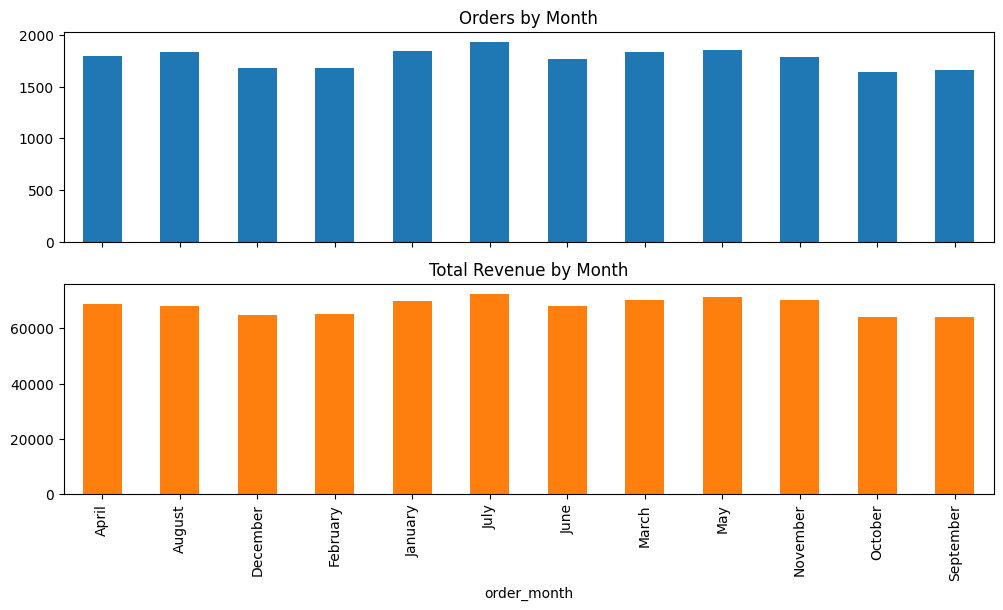

In [13]:
monthly = pizza_df.groupby('order_month').agg(
    orders=('order_id', 'nunique'), revenue=('total_price', 'sum')
)

monthly.plot(
    kind='bar',
    subplots=True,
    figsize=(12, 6),
    sharex=True,
    legend=False,
    title=['Orders by Month', 'Total Revenue by Month'],
)

#### % Sales per Category

<Axes: title={'center': '% of Sales by Category'}, xlabel='pizza_category'>

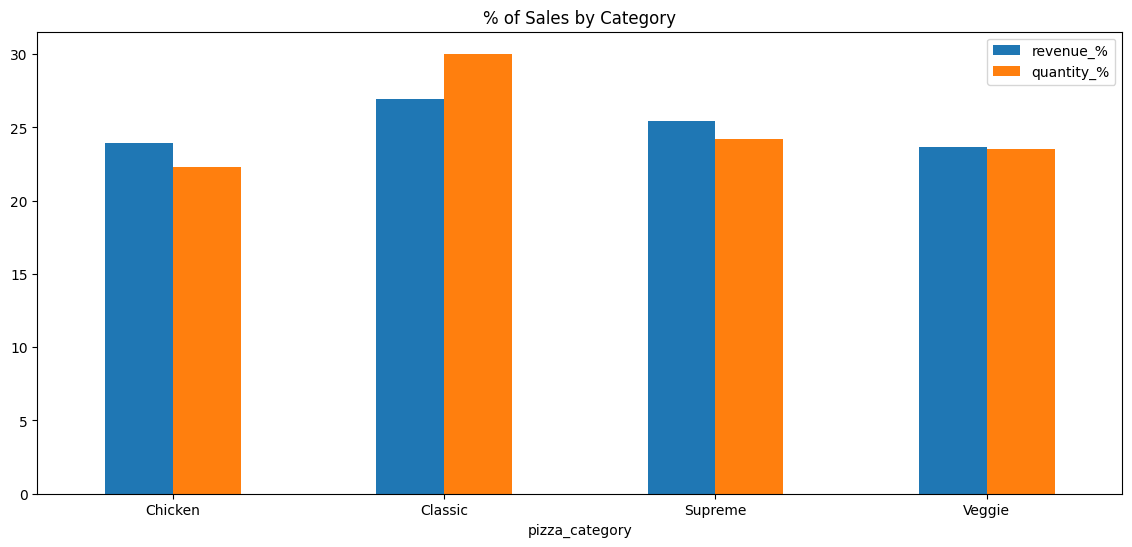

In [14]:
cat_df = pizza_df.groupby('pizza_category').agg(
    revenue=('total_price', 'sum'), quantity=('quantity', 'sum')
)
# حساب النسب المئوية في سطرين
cat_df['revenue_%'] = cat_df['revenue'] / cat_df['revenue'].sum() * 100
cat_df['quantity_%'] = cat_df['quantity'] / cat_df['quantity'].sum() * 100
# رسم النسب في عمودين جنب بعض
cat_df[['revenue_%', 'quantity_%']].plot(
    kind='bar', figsize=(14, 6), rot=0, title='% of Sales by Category'
)

#### % Sales per Size

<Axes: title={'center': '% of Sales by Size'}, xlabel='pizza_size'>

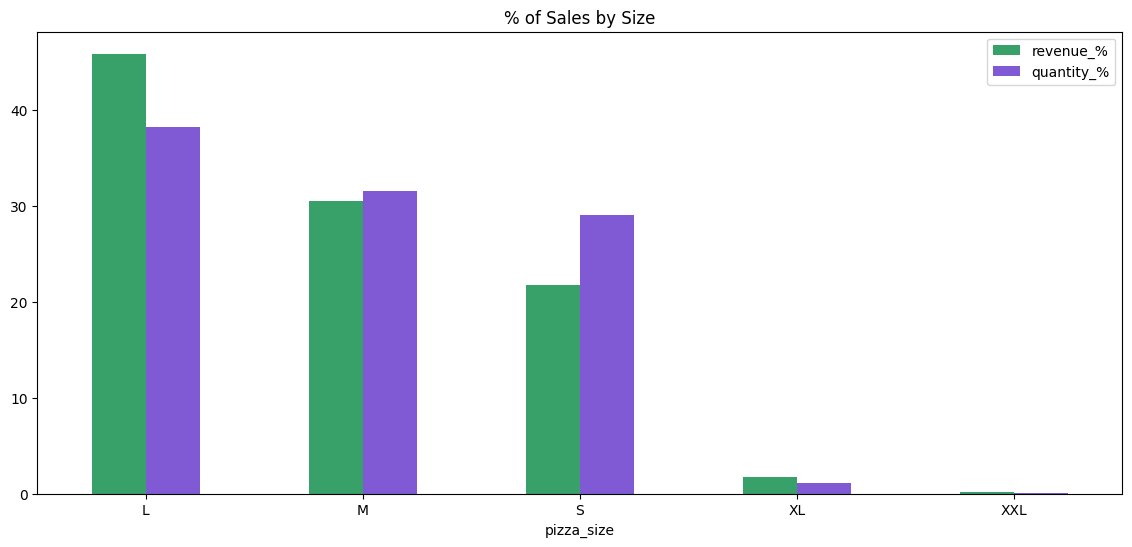

In [15]:
Size = pizza_df.groupby('pizza_size').agg(
    revenue=('total_price', 'sum'), quantity=('quantity', 'sum')
)
# حساب النسب المئوية في سطرين
Size['revenue_%'] = Size['revenue'] / Size['revenue'].sum() * 100
Size['quantity_%'] = Size['quantity'] / Size['quantity'].sum() * 100
# رسم النسب في عمودين جنب بعض
Size[['revenue_%', 'quantity_%']].plot(
    kind='bar',
    figsize=(14, 6),
    rot=0,
    title='% of Sales by Size',
    color=['#38a169', '#805ad5']
)

#### Pizza Sold per Category

<Axes: title={'center': 'Total Pizza Sold per Category'}, xlabel='pizza_category'>

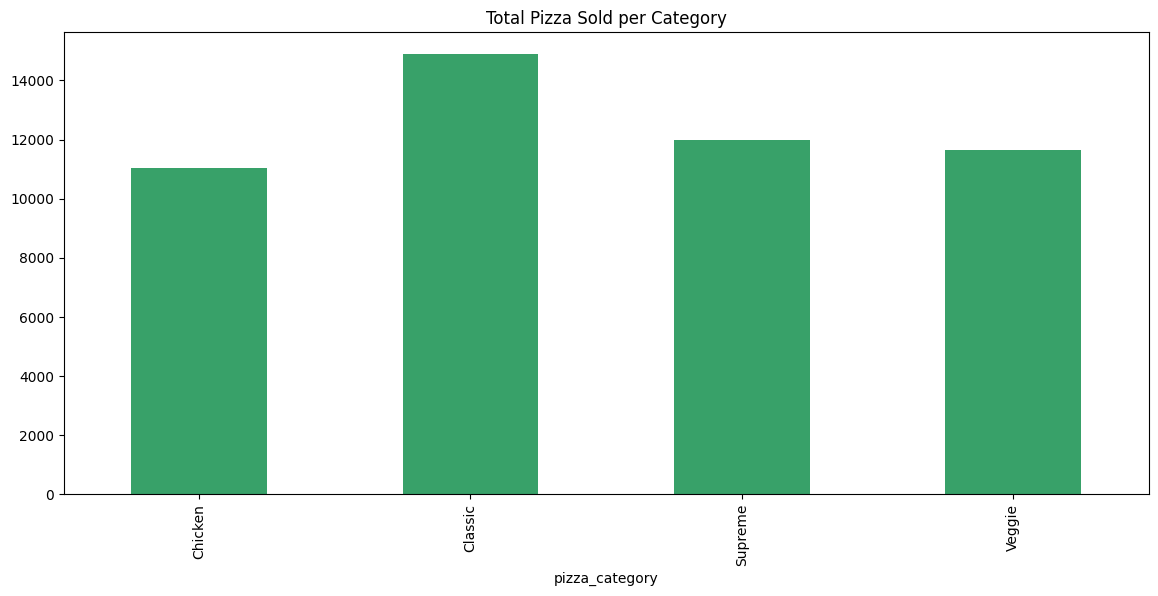

In [16]:
pizza_sold_category = pizza_df.groupby('pizza_category')['quantity'].sum()
pizza_sold_category.plot(
    kind='bar',
    title='Total Pizza Sold per Category',
    figsize=(14, 6),
    color='#38a169'
)

#### Top 5 best Selling Pizza

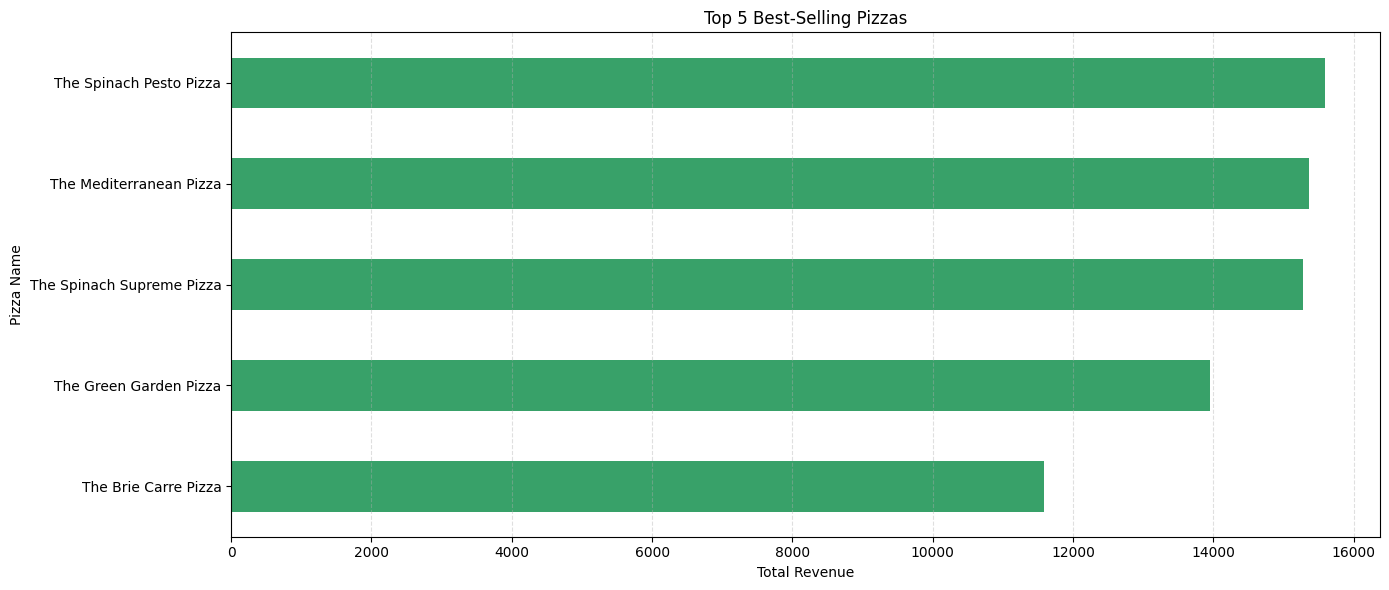

In [17]:
top_5_pizza = pizza_df.groupby('pizza_name')['total_price'].sum().sort_values(ascending=True).head(5)

ax = top_5_pizza.plot(
    kind='barh',
    figsize=(14, 6),
    color='#38a169',
    title='Top 5 Best-Selling Pizzas',
)

ax.set_xlabel('Total Revenue')
ax.set_ylabel('Pizza Name')
ax.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

#### Bottom 5 worest Selling Pizza

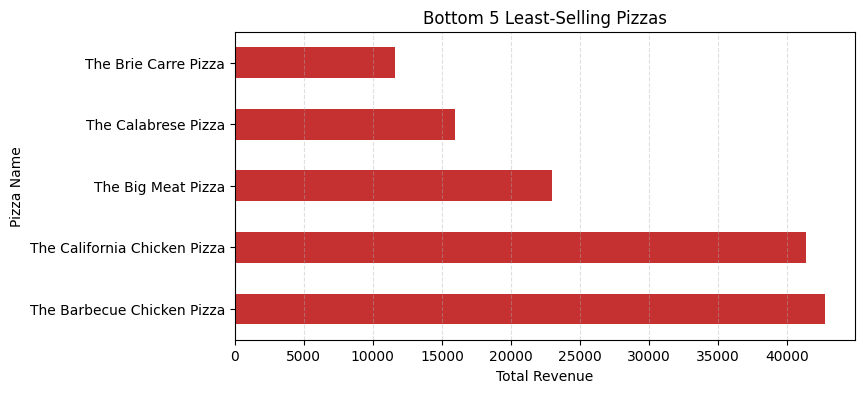

In [18]:
bottom5 = (
    pizza_df.groupby('pizza_name', as_index=True)['total_price']
    .sum()
    .head(5)  # أقل 5
    .sort_values(ascending=False)  # الأقل خالص يظهر فوق في الرسم الأفقي
)

ax = bottom5.plot(
    kind='barh',
    figsize=(8, 4),
    color='#c53030',
    title='Bottom 5 Least-Selling Pizzas',
)
ax.set_xlabel('Total Revenue')
ax.set_ylabel('Pizza Name')
ax.grid(axis='x', linestyle='--', alpha=0.4)